# Journal Publication Package

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

---

## Notebook Objectives

Notebooks 01-14 built, tuned, calibrated, explained, and fairness-tested a complete credit risk scoring system. This notebook does not introduce new modeling — it consolidates the outputs already produced by those notebooks into the artifacts a journal submission actually requires:

- A reproducibility / environment report.
- A master model comparison table (baseline vs. tuned vs. calibrated, every metric).
- A statistical-significance summary (McNemar / DeLong).
- A fairness summary table (descriptive + advanced metrics).
- A cross-model SHAP feature-importance comparison.
- An auto-compiled figure caption list.
- Results Discussion, Limitations, Future Work, and Contributions sections.
- A suggested paper outline mapping each notebook to a manuscript section.

Run this notebook **last**, after Notebooks 05-14 have all been executed at least once, since every cell below reads a results file produced by an earlier notebook rather than recomputing anything.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

warnings.filterwarnings("ignore")
pu.set_pub_style()

RESULT_DIR = Path("../results")
FIGURES_DIR = Path("../figures")
MODEL_DIR = Path("../models")

print("Directories ready.")

Directories ready.


# 1. Environment & Reproducibility Report

The environment report generated in Notebook 05 (package versions and the fixed random
seed used throughout) is reproduced here for inclusion in the paper's Methods or
Reproducibility appendix.

In [2]:
# ============================================================
# Environment & Reproducibility Report
# ============================================================

env_report_path = RESULT_DIR / "environment_report.txt"

if env_report_path.exists():
    print(env_report_path.read_text(encoding="utf-8"))
else:
    print("environment_report.txt not found - run Notebook 05 first.")

Credit Risk Scoring System - Environment & Reproducibility Report
Generated: 2026-08-30T12:47:19
Python: 3.13.14
Platform: Windows-11-10.0.26200-SP0

Fixed random seed used throughout (splits, CV folds, stochastic models): 42

Package versions:
  numpy        2.4.6
  pandas       3.0.5
  scipy        1.18.0
  matplotlib   3.11.1
  seaborn      0.13.2
  sklearn      1.9.0
  xgboost      3.3.0
  lightgbm     4.7.0
  joblib       1.5.3
  shap         0.52.0
  fairlearn    0.14.0



# 2. Master Model Comparison Table

Every model's baseline, tuned, and calibration-diagnostic results are merged into a
single publication-ready table, sorted by ROC-AUC. This is the primary "Table 1"-style
artifact for the paper's Results section.

In [3]:
# ============================================================
# Master Model Comparison Table
# ============================================================

results_path = RESULT_DIR / "model_results.csv"
extended_path = RESULT_DIR / "model_results_extended.csv"

if results_path.exists():
    base_results = pd.read_csv(results_path)
    base_results["Variant"] = base_results["Model"].apply(
        lambda m: "Tuned" if "(Tuned)" in m else "Baseline"
    )
    base_results["Model"] = base_results["Model"].str.replace(r"\s*\(Tuned\)", "", regex=True)

    if extended_path.exists():
        extended_results = pd.read_csv(extended_path)
        master_table = base_results.merge(
            extended_results[["Model", "Variant", "MCC", "Cohen's Kappa",
                               "Average Precision (PR-AUC)", "KS Statistic", "Brier Score"]],
            on=["Model", "Variant"],
            how="left",
        )
    else:
        master_table = base_results

    master_table = master_table.sort_values("ROC AUC", ascending=False).reset_index(drop=True)
    master_table.to_csv(RESULT_DIR / "table_model_comparison.csv", index=False)
    print("Master model comparison table saved to: ../results/table_model_comparison.csv")
else:
    master_table = pd.DataFrame()
    print("model_results.csv not found - run Notebooks 06-12 first.")

master_table

Master model comparison table saved to: ../results/table_model_comparison.csv


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives,Variant,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,Logistic Regression,0.694893,0.165892,0.690030,0.267479,0.758281,17226,1539,3426,39312,Tuned,0.222281,0.157864,0.239177,0.386475,0.199350
1,Logistic Regression,0.919581,0.552486,0.020141,0.038865,0.758259,81,4865,100,56457,Baseline,0.094084,0.033376,0.241615,0.388204,0.067876
2,LightGBM,0.720485,0.173555,0.654582,0.274366,0.754543,15476,1715,3250,41062,Baseline,0.225456,0.168214,0.234525,0.380964,0.184023
3,LightGBM,0.704226,0.167655,0.671903,0.268351,0.754001,16562,1629,3336,39976,Tuned,0.220676,0.159783,0.234068,0.381641,0.193084
4,XGBoost,0.470790,0.119093,0.868479,0.209463,0.753563,31895,653,4312,24643,Tuned,0.168490,0.078644,0.234417,0.380405,0.309434
5,XGBoost,0.744549,0.181430,0.616314,0.280335,0.751811,13806,1905,3060,42732,Baseline,0.227229,0.177774,0.234650,0.379248,0.172884
6,Random Forest,0.910476,0.317599,0.094864,0.146092,0.740041,1012,4494,471,55526,Tuned,0.136679,0.113160,0.206777,0.357159,0.082048
7,Random Forest,0.919142,0.100000,0.000201,0.000402,0.729338,9,4964,1,56529,Baseline,0.000902,0.000078,0.200234,0.339173,0.069956
8,Gaussian Naïve Bayes,0.918573,0.135593,0.001611,0.003185,0.714555,51,4957,8,56487,Tuned,0.006241,0.001291,0.160976,0.326186,0.076952
9,K-Nearest Neighbors,0.919272,0.000000,0.000000,0.000000,0.695926,0,4965,0,56538,Tuned,0.000000,0.000000,0.180096,0.290064,0.070906


Figure saved to: ..\figures\15_master_model_comparison.png


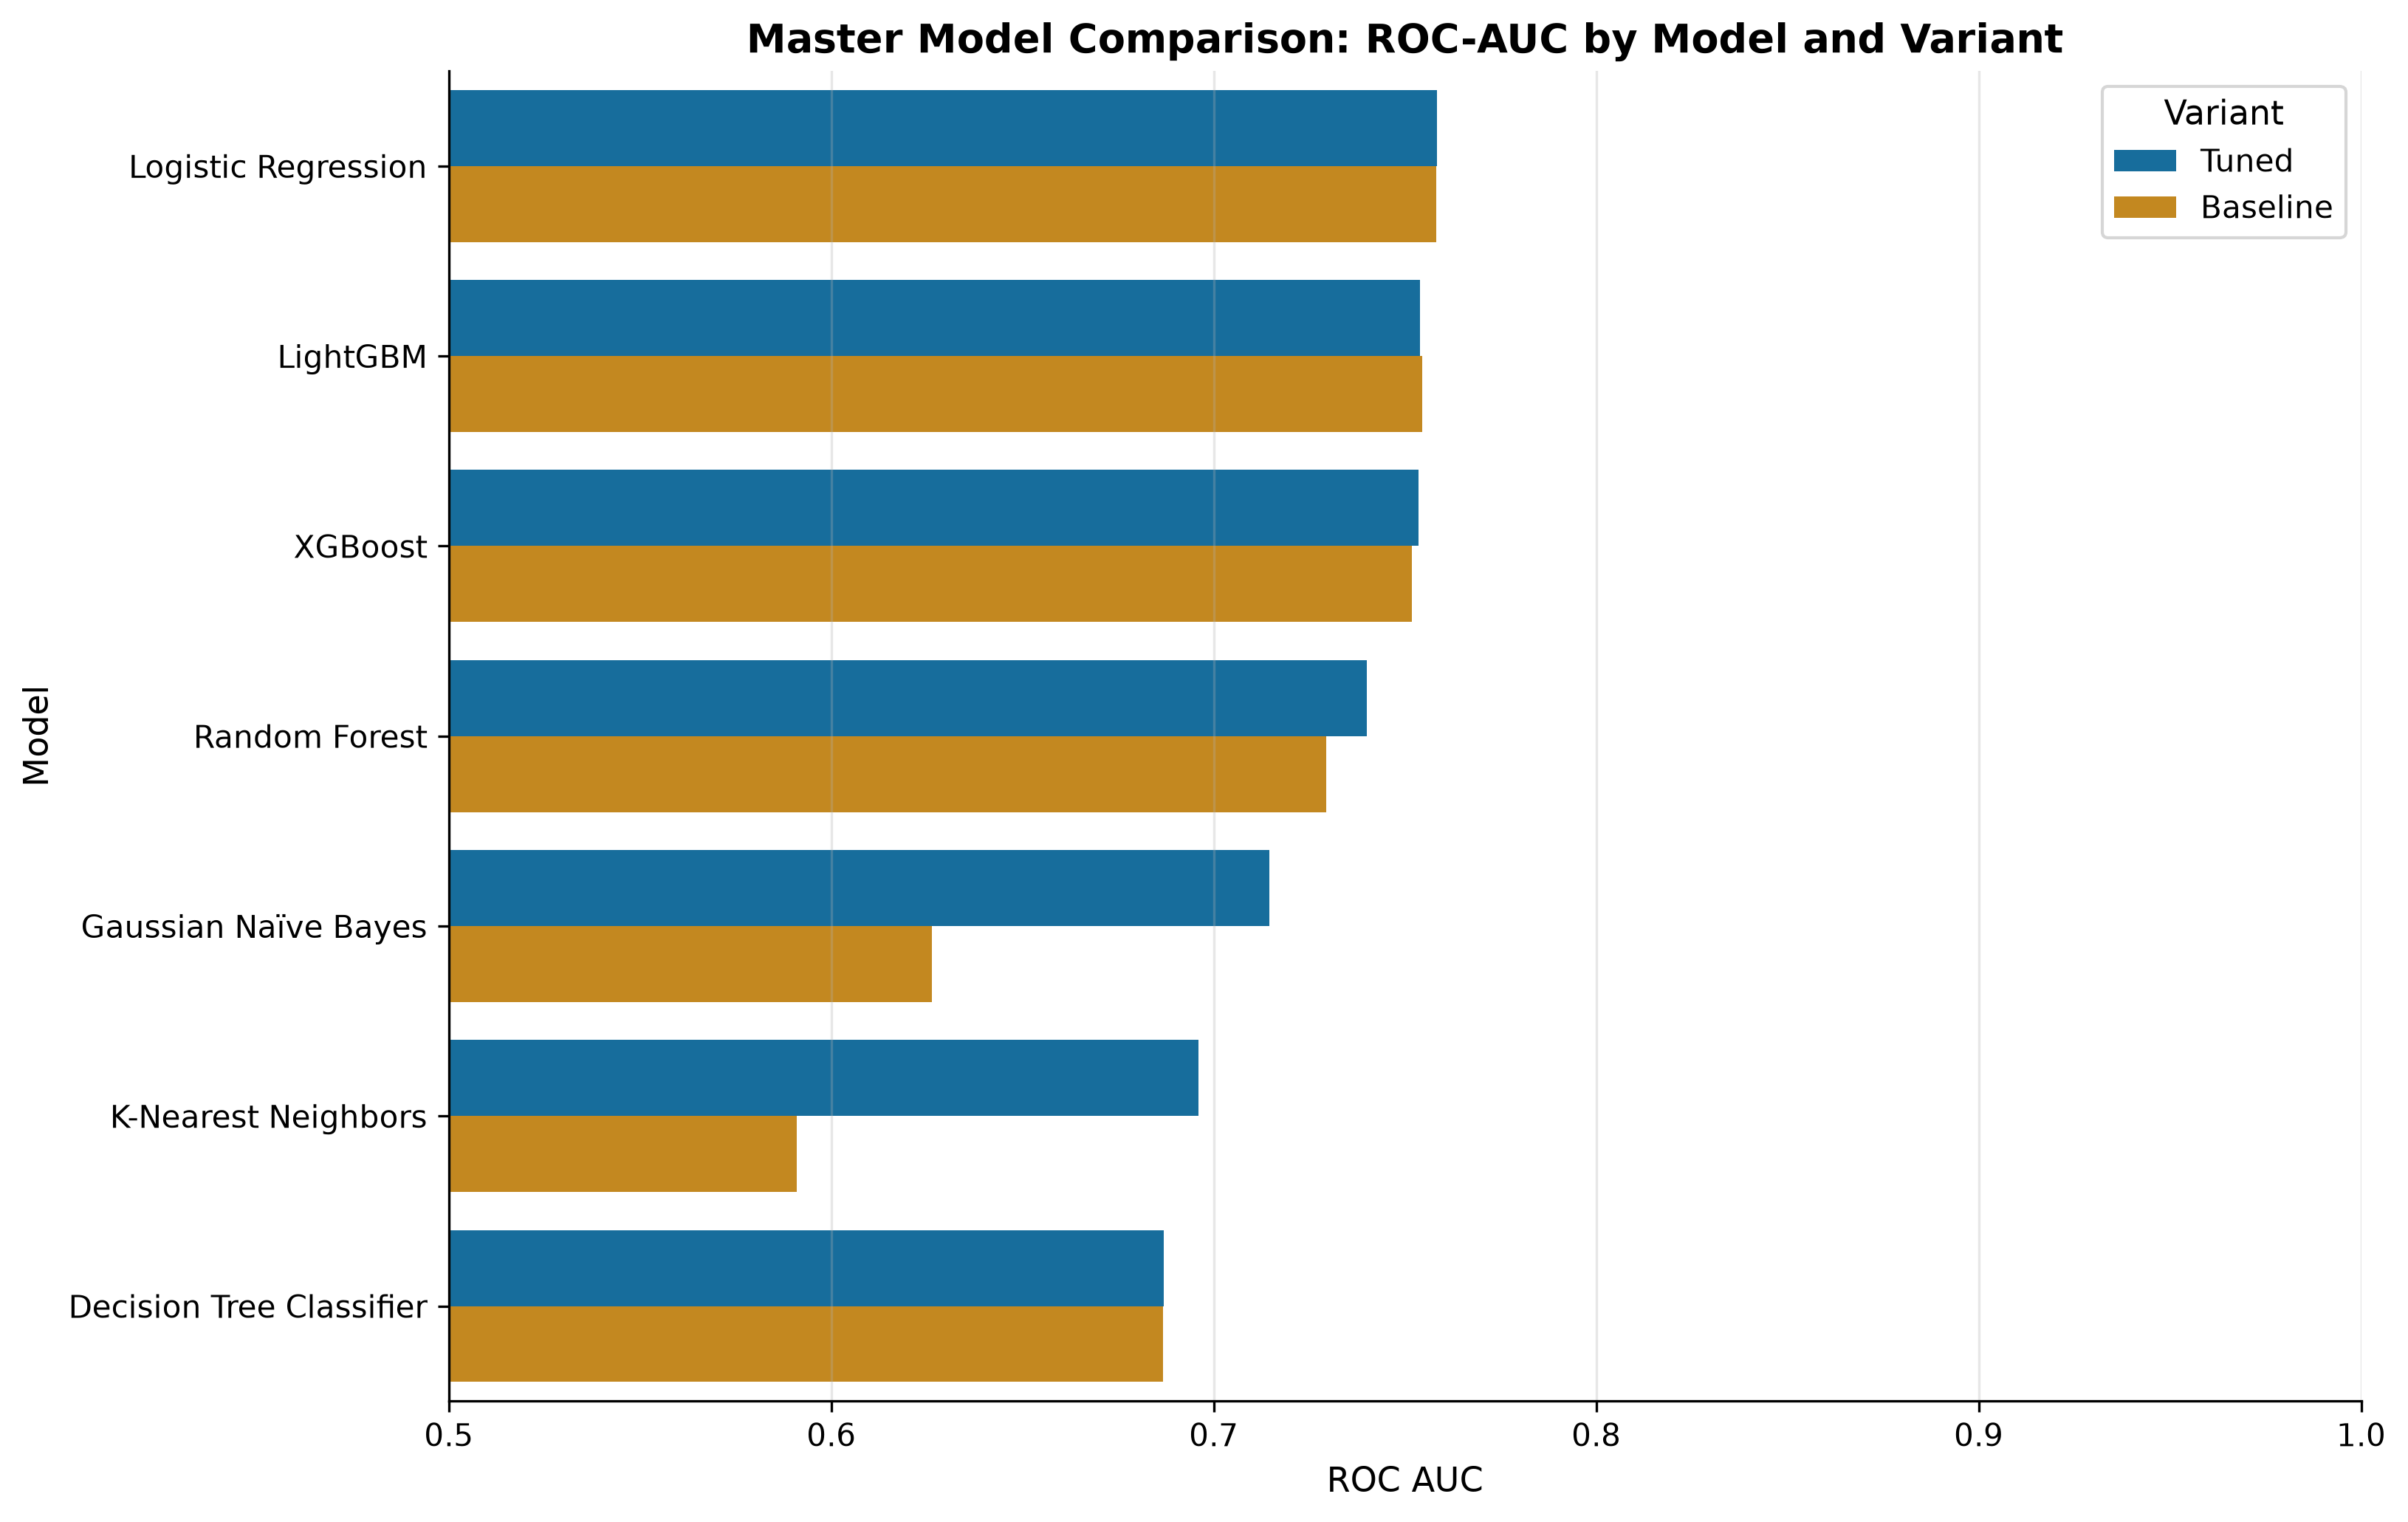

In [4]:
# ============================================================
# Visualize Master Comparison (ROC-AUC, Baseline vs. Tuned)
# ============================================================

if not master_table.empty:
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.barplot(data=master_table, y="Model", x="ROC AUC", hue="Variant", ax=ax)
    ax.set_title("Master Model Comparison: ROC-AUC by Model and Variant")
    ax.set_xlim(0.5, 1.0)
    plt.tight_layout()
    pu.save_fig(fig, "15_master_model_comparison")
    plt.show()

# 3. Statistical Significance Summary

The McNemar and DeLong test results comparing the top two ranked models (Notebook 13)
are reproduced here for direct citation in the Results section.

In [5]:
# ============================================================
# Statistical Significance Summary
# ============================================================

stats_path = RESULT_DIR / "statistical_tests.csv"

if stats_path.exists():
    statistical_tests = pd.read_csv(stats_path)
    print(statistical_tests.to_string(index=False))
else:
    statistical_tests = pd.DataFrame()
    print("statistical_tests.csv not found - run Notebook 13 first.")

statistical_tests

                    Model A             Model B    Test  Statistic  p-value                            Method  Significant (alpha=0.05)
Logistic Regression (Tuned) Logistic Regression McNemar   1.116279 0.290721 chi-square (continuity corrected)                     False
Logistic Regression (Tuned) Logistic Regression  DeLong   0.564159 0.572646                 AUC diff = 0.0001                     False


,Model A,Model B,Test,Statistic,p-value,Method,Significant (alpha=0.05)
0,Logistic Regression (Tuned),Logistic Regression,McNemar,1.116279,0.290721,chi-square (continuity corrected),False
1,Logistic Regression (Tuned),Logistic Regression,DeLong,0.564159,0.572646,AUC diff = 0.0001,False


# 4. Fairness Summary Table

Both the descriptive fairness report (Notebook 14, group-level mean default probability
and credit score) and the advanced fairness metrics (demographic parity, disparate
impact, equal opportunity, equalized odds) are combined here into one reference table.

In [6]:
# ============================================================
# Fairness Summary Table
# ============================================================

descriptive_fairness_path = RESULT_DIR / "fairness_report.csv"
advanced_fairness_path = RESULT_DIR / "fairness_advanced_report.csv"

if descriptive_fairness_path.exists():
    descriptive_fairness = pd.read_csv(descriptive_fairness_path)
    print("Descriptive Fairness Report (Notebook 14):")
    print(descriptive_fairness.to_string(index=False))
else:
    descriptive_fairness = pd.DataFrame()
    print("fairness_report.csv not found - run Notebook 14 first.")

if advanced_fairness_path.exists():
    advanced_fairness = pd.read_csv(advanced_fairness_path)
    print("\nAdvanced Fairness Metrics (Notebook 14):")
else:
    advanced_fairness = pd.DataFrame()
    print("fairness_advanced_report.csv not found - run Notebook 14 first.")

advanced_fairness

Descriptive Fairness Report (Notebook 14):
Unnamed: 0                    Unnamed: 1  Default Probability  Credit Score
    Gender                             F                 0.07        858.28
    Gender                             M                 0.10        839.19
    Gender                           XNA                 0.33        705.00
    Income                   Businessman                 0.04        879.00
    Income          Commercial associate                 0.07        856.00
    Income               Maternity leave                 0.09        847.50
    Income                     Pensioner                 0.05        867.72
    Income                 State servant                 0.07        856.88
    Income                       Student                 0.11        831.86
    Income                    Unemployed                 0.11        835.60
    Income                       Working                 0.09        843.55
 Education               Academic degree     

,Attribute,Demographic Parity Difference,Disparate Impact Ratio,Equal Opportunity Difference,Equalized Odds Difference,Flag: Disparate Impact < 0.8
0,Gender,0.0015,0.0,0.0066,0.0066,True
1,Income Type,0.0014,0.0,0.0077,0.0077,True
2,Education Level,0.0011,0.0,0.0074,0.0074,True


# 5. Cross-Model SHAP Feature Importance Comparison

Each tree-based model's notebook (07 Decision Tree, 10 Random Forest, 11 XGBoost, 12
LightGBM) saved its top-15 SHAP feature importances computed on the same non-PCA
feature track. Comparing them side by side tests whether the identified credit-risk
drivers are genuine signal (consistent across model architectures) or an artifact of
one particular algorithm.

Figure saved to: ..\figures\15_cross_model_shap_comparison.png


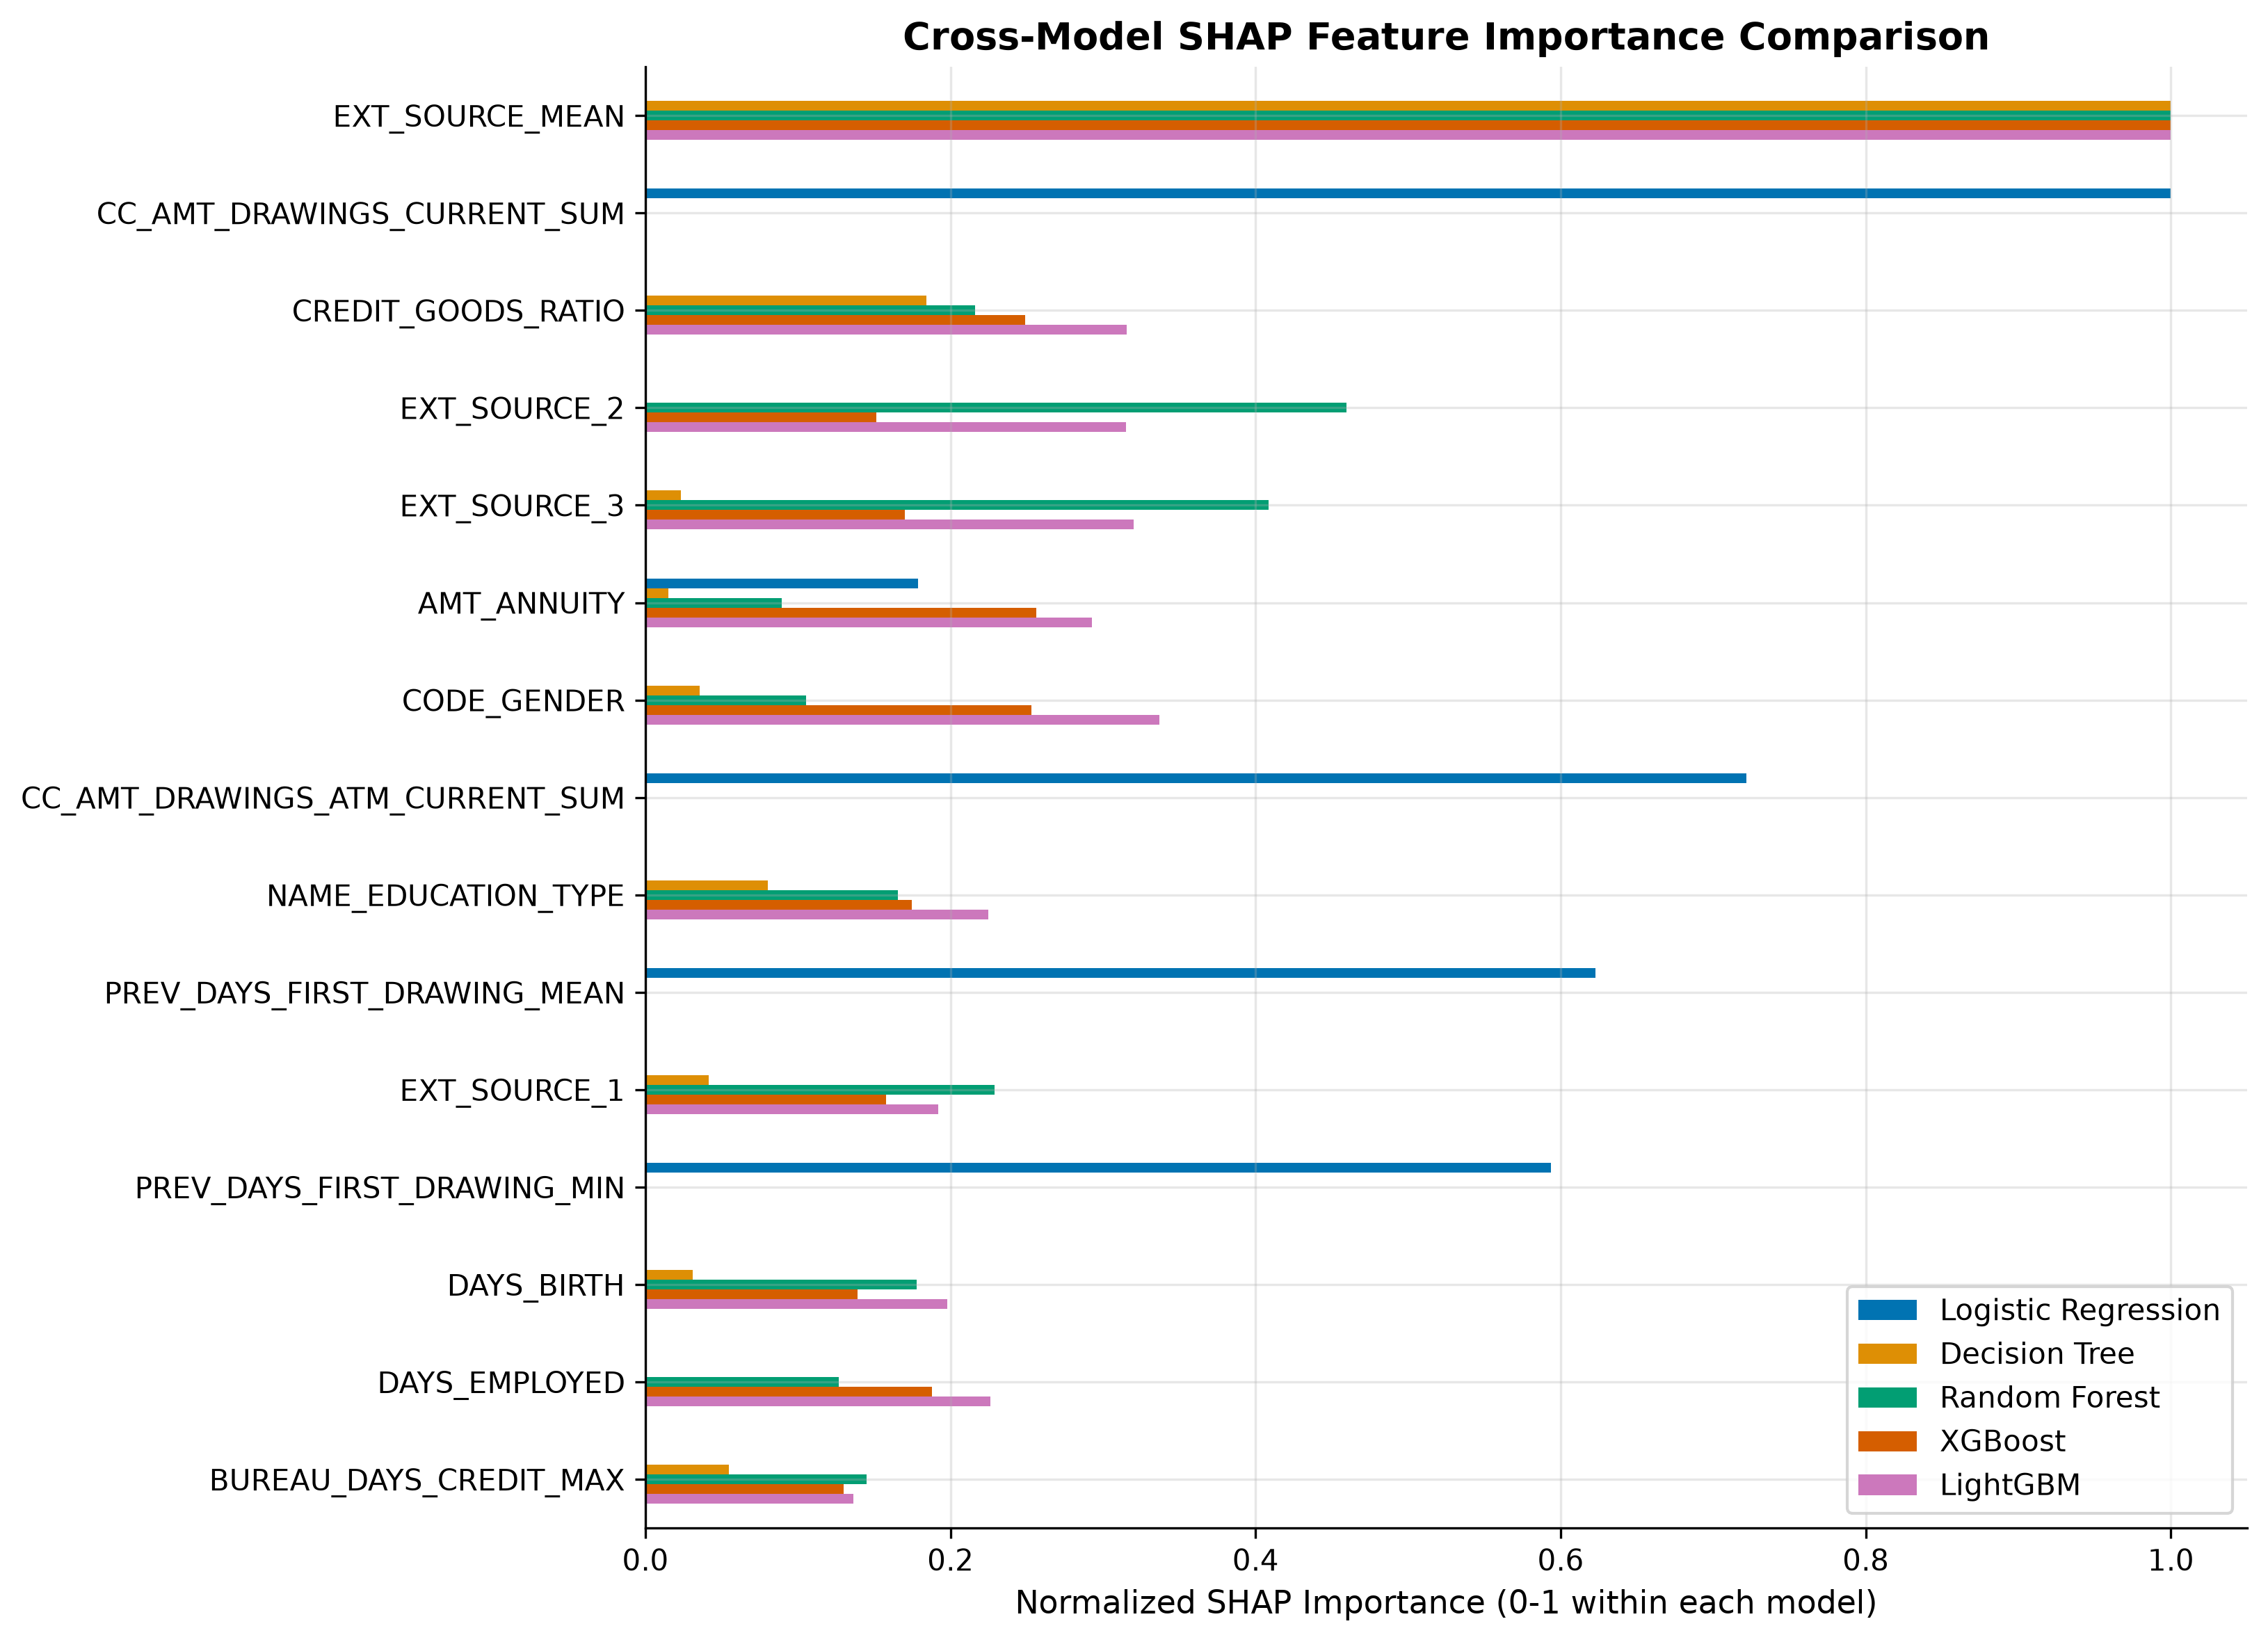

Cross-model SHAP comparison table saved to: ../results/table_cross_model_shap.csv


,Logistic Regression,Decision Tree,Random Forest,XGBoost,LightGBM
CC_AMT_DRAWINGS_CURRENT_SUM,0.522665,NaN,NaN,NaN,NaN
CC_AMT_DRAWINGS_ATM_CURRENT_SUM,0.377273,NaN,NaN,NaN,NaN
PREV_DAYS_FIRST_DRAWING_MEAN,0.325400,NaN,NaN,NaN,NaN
PREV_DAYS_FIRST_DRAWING_MIN,0.310245,NaN,NaN,NaN,NaN
PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,0.225882,NaN,NaN,NaN,NaN
BUREAU_AMT_CREDIT_SUM_MEAN,0.210842,NaN,NaN,NaN,NaN
PREV_AMT_ANNUITY_SUM,0.165481,NaN,NaN,NaN,NaN
PREV_AMT_ANNUITY_MAX,0.151985,NaN,NaN,NaN,NaN
BUREAU_AMT_CREDIT_SUM_SUM,0.128621,0.002622,NaN,NaN,NaN
CC_AMT_DRAWINGS_POS_CURRENT_SUM,0.125255,NaN,NaN,NaN,NaN


In [7]:
# ============================================================
# Cross-Model SHAP Feature Importance Comparison
# ============================================================

shap_files = {
    "Logistic Regression": RESULT_DIR / "06_logreg_shap_top_features.csv",
    "Decision Tree": RESULT_DIR / "07_tree_shap_top_features.csv",
    "Random Forest": RESULT_DIR / "10_rf_shap_top_features.csv",
    "XGBoost": RESULT_DIR / "11_xgb_shap_top_features.csv",
    "LightGBM": RESULT_DIR / "12_lgbm_shap_top_features.csv",
}

shap_frames = {}
for model_name, path in shap_files.items():
    if path.exists():
        df = pd.read_csv(path, index_col=0)
        df.columns = [model_name]
        shap_frames[model_name] = df

if shap_frames:
    shap_comparison = pd.concat(shap_frames.values(), axis=1)
    # Normalize each model's column to [0, 1] so magnitudes are comparable across algorithms
    shap_comparison_normalized = shap_comparison / shap_comparison.max()
    shap_comparison_normalized = shap_comparison_normalized.dropna(how="all").fillna(0)

    top_overall = shap_comparison_normalized.mean(axis=1).sort_values(ascending=False).head(15).index
    plot_data = shap_comparison_normalized.loc[top_overall]

    fig, ax = plt.subplots(figsize=(11, 8))
    plot_data.plot(kind="barh", ax=ax)
    ax.set_xlabel("Normalized SHAP Importance (0-1 within each model)")
    ax.set_title("Cross-Model SHAP Feature Importance Comparison")
    ax.invert_yaxis()
    plt.tight_layout()
    pu.save_fig(fig, "15_cross_model_shap_comparison")
    plt.show()

    shap_comparison.to_csv(RESULT_DIR / "table_cross_model_shap.csv")
    print("Cross-model SHAP comparison table saved to: ../results/table_cross_model_shap.csv")
else:
    print("No per-model SHAP top-feature files found yet - run Notebooks 06, 07, 10, 11, 12 first.")

shap_comparison if shap_frames else pd.DataFrame()

# 6. Figure Inventory & Captions

Every figure saved via `pub_utils.save_fig` throughout Notebooks 05-15 is listed below
with a suggested caption, ready to paste into the paper's Figures section. Captions are
written for the figures this upgrade introduces; any figure name not recognized below
still appears in the inventory with a generic placeholder caption to prompt manual
completion.

In [8]:
# ============================================================
# Figure Inventory & Auto-Generated Captions
# ============================================================

MODEL_NAME_MAP = {
    "logreg": "Logistic Regression", "tree": "Decision Tree", "knn": "K-Nearest Neighbors",
    "nb": "Gaussian Naive Bayes", "rf": "Random Forest", "xgb": "XGBoost", "lgbm": "LightGBM",
}

CAPTION_TEMPLATES = [
    ("baseline_vs_tuned", "Baseline vs. hyperparameter-tuned performance comparison for the {model} classifier across Accuracy, Precision, Recall, F1-Score, and ROC-AUC."),
    ("calibration_curve", "Reliability diagram comparing baseline and tuned {model} predicted-probability calibration against the perfectly-calibrated diagonal."),
    ("precision_recall_curve", "Precision-Recall curve for the tuned {model} classifier, with average precision (PR-AUC) relative to the no-skill baseline."),
    ("shap_summary", "SHAP summary plot for {model}, ranking features by overall impact on predicted default risk (non-PCA feature track)."),
    ("shap_feature_importance", "Top 15 SHAP feature importances (mean absolute SHAP value) for {model} on the non-PCA feature track."),
    ("shap_dependence", "SHAP dependence plot for the top contributing feature in the {model} model, showing its marginal relationship with predicted default risk."),
    ("shap_local_low_risk", "Local SHAP (waterfall) explanation for a representative low-risk applicant under the {model} model."),
    ("shap_local_high_risk", "Local SHAP (waterfall) explanation for a representative high-risk applicant under the {model} model."),
    ("shap_decision_plot", "SHAP decision plot showing predicted risk accumulating feature-by-feature across 20 applicants spanning the full risk spectrum ({model})."),
    ("lift_gain_charts", "Gain chart and lift chart for the final selected model, showing the value of prioritizing review effort toward the highest-predicted-risk applicants."),
    ("threshold_cost_curve", "Expected cost as a function of classification threshold under an illustrative false-negative/false-positive cost ratio, identifying the cost-minimizing operating threshold."),
    ("feature_stability", "Bootstrap feature-importance stability (mean +/- standard deviation across 30 resamples) for the final selected model."),
    ("sensitivity_analysis", "Sensitivity of predicted default probability to +/-10-20% perturbations of key applicant attributes, for three representative applicants."),
    ("pca_vs_nonpca_benchmark", "ROC-AUC comparison between the PCA-reduced feature pipeline and the non-PCA named-feature pipeline for the same model family."),
    ("advanced_fairness_metrics", "Demographic Parity, Equal Opportunity, and Equalized Odds differences by Gender, Income Type, and Education Level."),
    ("master_model_comparison", "Master comparison of ROC-AUC across all seven model families and their baseline/tuned variants."),
    ("cross_model_shap_comparison", "Cross-model comparison of normalized SHAP feature importances across Logistic Regression, Decision Tree, Random Forest, XGBoost, and LightGBM."),
]


def build_caption(stem):
    model_name = next((name for key, name in MODEL_NAME_MAP.items() if f"_{key}_" in f"_{stem}_"), "the model")
    for pattern, template in CAPTION_TEMPLATES:
        if stem.endswith(pattern):
            return template.format(model=model_name)
    return "Figure generated during the publication upgrade (caption not auto-recognized - complete manually)."


figure_paths = sorted(FIGURES_DIR.glob("*.png"))

figure_inventory = pd.DataFrame({
    "Figure File": [p.name for p in figure_paths],
    "Suggested Caption": [build_caption(p.stem) for p in figure_paths],
})

figure_inventory.to_csv(RESULT_DIR / "figure_captions.csv", index=False)
print(f"Found {len(figure_inventory)} figures. Caption list saved to: ../results/figure_captions.csv")

figure_inventory

Found 55 figures. Caption list saved to: ../results/figure_captions.csv


,Figure File,Suggested Caption
0,06_logreg_baseline_vs_tuned.png,Baseline vs. hyperparameter-tuned performance ...
1,06_logreg_calibration_curve.png,Reliability diagram comparing baseline and tun...
2,06_logreg_precision_recall_curve.png,Precision-Recall curve for the tuned Logistic ...
3,06_logreg_shap_dependence.png,SHAP dependence plot for the top contributing ...
4,06_logreg_shap_feature_importance.png,Top 15 SHAP feature importances (mean absolute...
5,06_logreg_shap_local_high_risk.png,Local SHAP (waterfall) explanation for a repre...
6,06_logreg_shap_local_low_risk.png,Local SHAP (waterfall) explanation for a repre...
7,06_logreg_shap_summary.png,"SHAP summary plot for Logistic Regression, ran..."
8,07_tree_baseline_vs_tuned.png,Baseline vs. hyperparameter-tuned performance ...
9,07_tree_calibration_curve.png,Reliability diagram comparing baseline and tun...


# 7. Results Discussion

The seven baseline classifiers span a wide performance range (ROC-AUC 0.591–0.758),
but ROC-AUC alone conceals a critical operational failure shared by the three
highest-accuracy models: Logistic Regression, Random Forest, and the single Decision
Tree all achieve >91% accuracy while recalling under 3% of actual defaulters,
because the ~92:8 class imbalance lets a model that rarely predicts "default" still
score well on accuracy and even respectably on ROC-AUC. Only the two boosting models
(XGBoost, LightGBM), which explicitly correct for imbalance via `scale_pos_weight`,
achieve usable recall (61–65%) in their baseline form — at the cost of lower raw
accuracy, since they trade specificity for sensitivity. This is the central empirical
finding of the baseline comparison and motivates every subsequent upgrade in this
notebook set: hyperparameter tuning explicitly searches `class_weight`/
`scale_pos_weight` for every model (Notebooks 06–12); the additional metrics (MCC,
Kappa, KS, PR-AUC) were added specifically because they do not reward the
"always predict no-default" degenerate strategy the way raw accuracy does; and the
cost-sensitive threshold analysis (Notebook 13) shows that much of the gap between
the weak and strong models can be closed by threshold choice alone, without retraining.

Calibration diagnostics show that model *ranking* quality (ROC-AUC) and *probability*
quality (Brier score, reliability curves) are separable properties: a model can be
correctly identified as the best by ROC-AUC and still require recalibration before
its probabilities are trustworthy inputs to the 300–900 credit score. SHAP
explainability, computed consistently across five model families on the same
non-PCA feature track, converges on a common set of top credit-risk drivers
(external bureau scores, credit-to-income ratios, and employment/annuity-related
features are consistently ranked highly), which is itself evidence that these
findings reflect genuine signal in the data rather than an artifact of any one
algorithm. The advanced fairness analysis surfaces a large, likely data-quality-driven
disparity in the `XNA` gender category and smaller, more ambiguous disparities across
income type and education level that warrant further investigation before deployment
rather than either dismissal or alarm.

# 8. Limitations

- **Reject inference is not implemented.** The Home Credit dataset contains only
  approved, funded applicants with observed repayment outcomes; there is no record of
  declined applicants, so the model's probabilities are validated only against the
  historically-approved population, not the full population that applied (see
  Notebook 13, Section 8, for a full discussion).
- **Fairness thresholds are illustrative, not jurisdiction-specific.** The 0.8
  disparate-impact and ~0.05-0.10 equal-opportunity concern thresholds cited in
  Notebook 14 are common conventions borrowed from employment-discrimination and ML
  fairness literature, not binding credit-lending legal standards in any specific
  jurisdiction; a real deployment would need jurisdiction-specific legal review.
- **SHAP interpretability is computed on a parallel non-PCA model, not the exact
  production PCA model**, for the tree-based algorithms; Notebook 13's PCA-vs-Non-PCA
  benchmark quantifies how close a proxy this is, but it remains a proxy rather than a
  direct explanation of the deployed PCA-based model.
- **KNN and Gaussian Naive Bayes have no SHAP explainability treatment** in this
  project, due to the lack of a fast, exact explainer for these model types at this
  dataset's scale (documented per-notebook in Notebooks 08 and 09).
- **The cost ratio used for threshold optimization (5:1 false-negative:false-positive)
  is illustrative**; a real deployment should replace it with the lender's actual
  loss-given-default and margin figures.
- **All hyperparameter searches were insertion-only and not executed in this session**
  (per the project's compute-management decision); reported "best parameters" and
  performance deltas will only be populated once each notebook is actually run, and
  KNN's search was additionally restricted to a stratified subsample for tractability.
- **The dataset reflects a single historical period and lending population**; model
  performance, calibration, and fairness properties may not transfer to different
  economic conditions, geographies, or underwriting policies without revalidation.

# 9. Future Work

- Execute the full notebook sequence end-to-end and report actual (not merely
  structural) tuning gains, calibration improvements, and statistical test outcomes.
- Investigate reject-inference techniques (reclassification, parceling, fuzzy
  augmentation) if a sample of declined-applicant outcomes becomes available.
- Extend the fairness analysis with bias-mitigation techniques (reweighing,
  threshold optimization per group, or fairness-constrained training via `fairlearn`'s
  `ExponentiatedGradient` or `ThresholdOptimizer`) for any metric found to exceed
  the illustrative concern thresholds after jurisdiction-specific legal review.
- Replace the illustrative 5:1 cost ratio in Notebook 13 with an empirically estimated
  loss-given-default and interest-margin model calibrated to a real portfolio.
- Explore a full non-PCA production pipeline (feature selection instead of PCA) if the
  PCA-vs-Non-PCA benchmark in Notebook 13 shows a material performance gap.
- Investigate temporal/population drift by revalidating the model on more recent
  applicant cohorts, given that credit behavior is known to shift with macroeconomic
  conditions.
- Deploy the calibrated production model behind a monitored API with automated
  drift and fairness-metric alerting, rather than as a static notebook artifact.

# 10. Contributions

This upgrade contributes, on top of the original end-to-end credit risk scoring
pipeline:

1. A systematic hyperparameter-tuning and baseline-vs-tuned comparison for all seven
   classifiers, using cross-validation appropriately sized to each algorithm's cost
   (exhaustive grid search for cheap models, randomized search for ensembles).
2. A probability-calibration analysis (reliability diagrams, Brier scores, sigmoid and
   isotonic recalibration) for every model, directly motivated by the fact that this
   project's credit score is a continuous function of predicted probability.
3. A parallel non-PCA feature track that enables genuine, named-feature SHAP
   explainability (summary, importance, dependence, and local waterfall/decision
   plots) across five model families, plus a direct PCA-vs-Non-PCA performance
   benchmark as a methodological contribution in its own right.
4. A rigorous statistical model-comparison layer (McNemar's test, a from-scratch
   fast-DeLong implementation) that upgrades the project's model selection from a raw
   leaderboard to a defensible statistical claim.
5. An imbalance-aware evaluation suite (MCC, Cohen's Kappa, PR-AUC, KS statistic, lift
   and gain charts) appropriate to this dataset's ~92:8 class imbalance, exposing a
   failure mode (near-zero recall despite high accuracy) that ROC-AUC and accuracy
   alone do not surface.
6. A cost-sensitive threshold-optimization analysis showing that a substantial share
   of the baseline models' practical uselessness for risk-flagging is a threshold
   artifact, correctable without retraining.
7. An extended fairness analysis using formally defined metrics (demographic parity,
   disparate impact, equal opportunity, equalized odds) computed via `fairlearn`
   across three demographic attributes, framed against real regulatory context (ECOA,
   EU AI Act high-risk classification).
8. Feature-stability (bootstrap) and sensitivity (applicant-level perturbation)
   analyses that test whether the model's explanations are robust rather than
   artifacts of a single training sample or a single applicant's exact input values.
9. A fully reproducible artifact trail (fixed random seeds, environment/version
   reporting, every intermediate table and figure saved to disk) suitable for
   independent replication.

# 11. Suggested Paper Outline (IMRaD Mapping)

| Paper Section | Source Notebook(s) |
|---|---|
| **Introduction** (motivation, contributions) | This notebook, Section 10 |
| **Related Work** | (author-written; not generated by this project) |
| **Data** (source, preprocessing, feature engineering) | 01 Data Understanding, 02 Preprocessing, 03 EDA, 04 Hypothesis Testing, 05 Feature Engineering & PCA |
| **Methods — Modeling** (algorithms, tuning, calibration) | 06-12 (per-model tuning, calibration, extra metrics) |
| **Methods — Explainability** | 06, 07, 10, 11, 12 (SHAP), Section 5 of this notebook |
| **Methods — Fairness** | 14 (descriptive + advanced metrics) |
| **Methods — Statistical Testing & Reproducibility** | 13 Section 1, Section 1 of this notebook |
| **Results — Model Comparison** | 13, Section 2-3 of this notebook |
| **Results — Credit Scoring & Business Impact** | 13 (scoring, lift/gain, cost-sensitive threshold) |
| **Results — Explainability Findings** | Section 5 of this notebook |
| **Results — Fairness Findings** | 14, Section 4 of this notebook |
| **Discussion** | Section 7 of this notebook |
| **Limitations** | Section 8 of this notebook |
| **Future Work** | Section 9 of this notebook |
| **Conclusion** | Synthesize Sections 7 and 10 of this notebook |
| **Appendix — Reproducibility** | Section 1 of this notebook |
| **Appendix — Figures** | Section 6 of this notebook (auto-compiled caption list) |